In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Функция группировки продуктов

Объединение наименований продуктов в укрупнённые категории для обеспечения единообразия данных при обработке нескольких датасетов.

In [2]:
def group_product(product):
    product = product.lower()

    if 'visa' in product and 'instant' in product:
        return 'Visa Instant'
    elif 'элкарт' in product and 'instant' in product:
        return 'Элкарт Instant'
    elif 'visa' in product and 'gold' in product:
        return 'Visa Gold'
    elif 'visa business' in product or 'prime' in product:
        return 'Visa Premium'
    elif 'виртуальная карта' in product:
        return 'Элкарт виртуальная'
    else:
        return 'Элкарт+'

### Подготовка данных по выпущенным картам

Преобразование дат открытия карт в месячный формат, группировка продуктов и агрегация количества выпущенных карт по месяцу, филиалу, отделению, платежной системе и продукту. Результат сохраняется в CSV для дальнейшего анализа.

In [3]:
df = pd.read_parquet('Выпущенные.parquet')
df['Продукт'] = df['Продукт'].apply(group_product)
df['Дата открытия'] = pd.to_datetime(df['Дата открытия'])
df['Дата открытия'] = df['Дата открытия'].dt.to_period('M').astype(str)
df = df.rename(columns={'Дата открытия': 'Месяц'})
df = df.pivot_table(
    index=['Месяц', 'Филиал', 'Отделение', 'Платежная система', 'Продукт'],
    values='ID карты',
    aggfunc='count'
).reset_index()
df = df.rename(columns={'ID карты':'Количество карт'})
df.to_csv('Выпущенные.csv', index=False, encoding='utf-8-sig')

df = df.loc[:, df.columns != 'Unnamed: 0']
df

,Месяц,Филиал,Отделение,Платежная система,Продукт,Количество карт
0,2025-01,Балыкчинский филиал,Балыкчинский филиал,VISA,Visa Gold,15
1,2025-01,Балыкчинский филиал,Балыкчинский филиал,VISA,Visa Instant,54
2,2025-01,Балыкчинский филиал,Балыкчинский филиал,Элкарт,Элкарт Instant,47
3,2025-01,Балыкчинский филиал,Балыкчинский филиал,Элкарт,Элкарт+,14
4,2025-01,Балыкчинский филиал,"Сберегательная касса ""Ананьево"" №053-04-22",VISA,Visa Instant,246
...,...,...,...,...,...,...
4614,2025-12,Чуйский филиал,"Сберегательная касса ""Сокулук"" №053-08-52",Элкарт,Элкарт+,7
4615,2025-12,Чуйский филиал,Чуйский филиал,VISA,Visa Gold,2
4616,2025-12,Чуйский филиал,Чуйский филиал,VISA,Visa Instant,373
4617,2025-12,Чуйский филиал,Чуйский филиал,Элкарт,Элкарт Instant,352


### Динамика выпуска карт по месяцам

Анализ изменения количества выпущенных карт по месяцам. Столбцы отображают объём выпуска, линия — процентное изменение относительно предыдущего месяца.

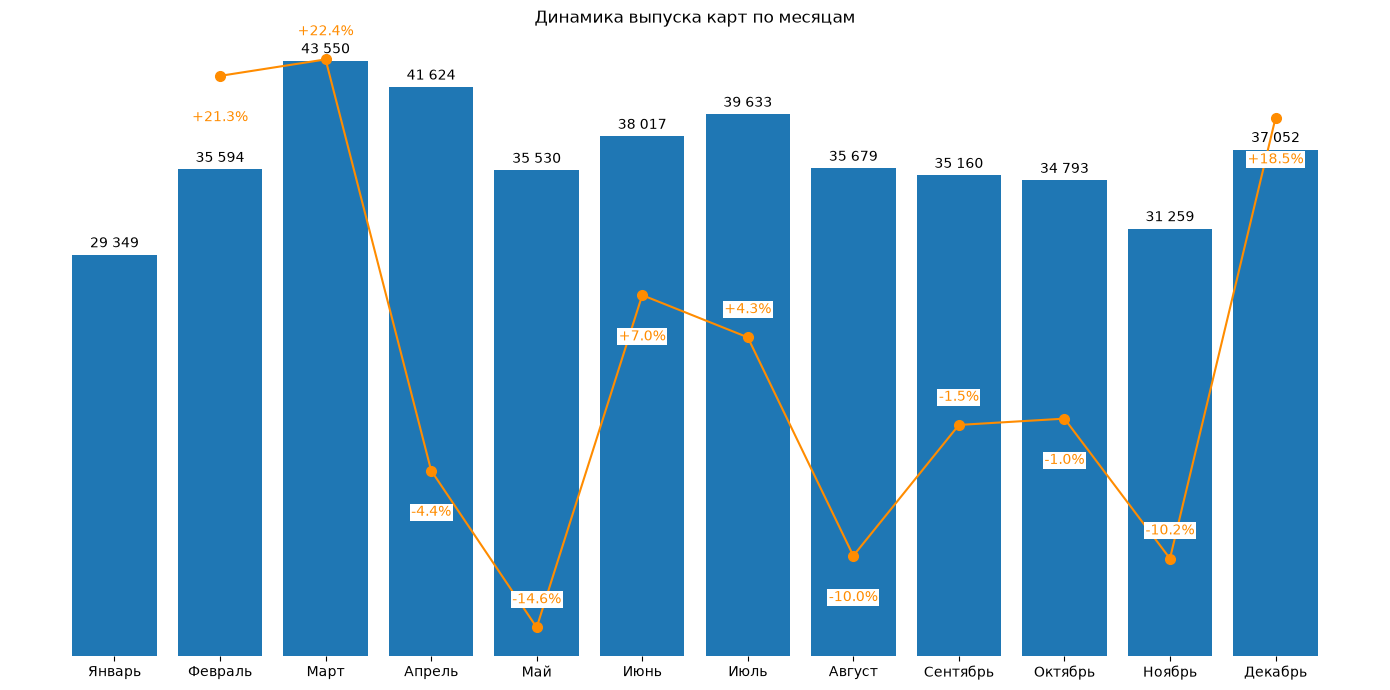

In [4]:
df = pd.read_csv('Выпущенные.csv')
df = df.groupby('Месяц', as_index=False)['Количество карт'].sum()

# Сортируем по дате
df['Месяц'] = pd.to_datetime(df['Месяц'])
df = df.sort_values('Месяц')

# Названия месяцев
месяцы = {
    1: 'Январь', 2: 'Февраль', 3: 'Март',
    4: 'Апрель', 5: 'Май', 6: 'Июнь',
    7: 'Июль', 8: 'Август', 9: 'Сентябрь',
    10: 'Октябрь', 11: 'Ноябрь', 12: 'Декабрь'
}

x = range(len(df))
labels = df['Месяц'].dt.month.map(месяцы)

# Процент изменения относительно предыдущего месяца
df['Изменение, %'] = (
    df['Количество карт'].pct_change() * 100
)

fig, ax1 = plt.subplots(figsize=(14, 7))

# Столбцы
bars = ax1.bar(
    x,
    df['Количество карт']
)

# Подписи над столбцами
ax1.bar_label(
    bars,
    labels=[
        f'{value:,.0f}'.replace(',', ' ')
        for value in df['Количество карт']
    ],
    padding=3
)

ax1.set_xticks(list(x))
ax1.set_xticklabels(labels)
ax1.set_yticks([])

# Линия процента изменения
ax2 = ax1.twinx()

ax2.plot(
    list(x),
    df['Изменение, %'],
    color='darkorange',
    marker='o',
    markersize=7
)

# Подписи процентов над кружками
for i, value in enumerate(df['Изменение, %']):
    if pd.notna(value):
        if i % 2 == 0:
            offset = 15
            va = 'bottom'
        else:
            offset = -25
            va = 'top'

        ax2.annotate(
            f'{value:+.1f}%',
            (i, value),
            xytext=(0, offset),
            textcoords='offset points',
            ha='center',
            va=va,
            color='darkorange',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                pad=1
            )
        )

ax2.set_yticks([])

plt.title('Динамика выпуска карт по месяцам')
ax1.set_frame_on(False)
ax2.set_frame_on(False)
plt.tight_layout()
plt.show()

### Диаграмма Парето выпуска карт по филиалам

Анализ распределения общего объёма выпуска карт между филиалами. Филиалы ранжируются по количеству выпущенных карт, а накопленная доля показывает их совокупный вклад в общий объём выпуска.

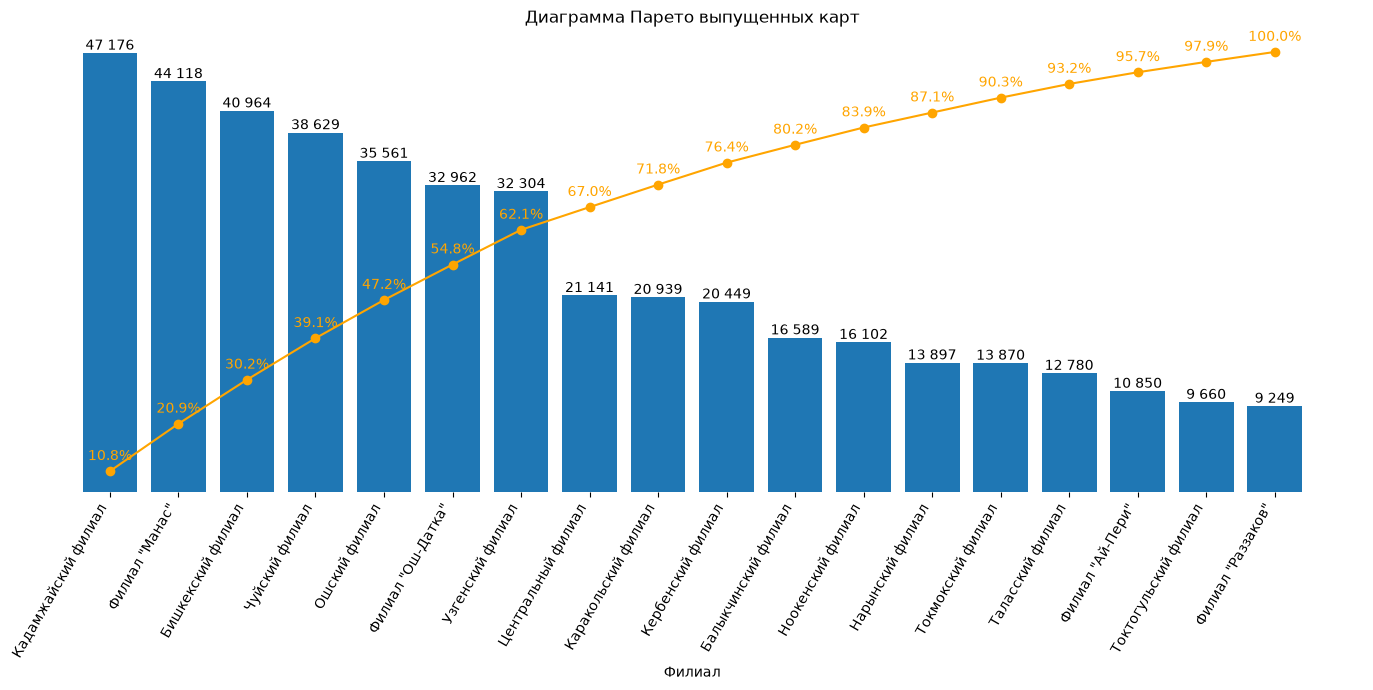

In [5]:
df = pd.read_csv('Выпущенные.csv')
pareto = df.groupby('Филиал', as_index=False)['Количество карт'].sum()

pareto = pareto.sort_values('Количество карт', ascending=False)

pareto['Накопленная доля'] = (pareto['Количество карт'].cumsum() / pareto['Количество карт'].sum() * 100)

x = range(len(pareto))

fig, ax1 = plt.subplots(figsize=(14, 7))

# Столбцы
bars = ax1.bar(
    x,
    pareto['Количество карт']
)

ax1.set_xlabel('Филиал')
ax1.set_xticks(x)
ax1.set_xticklabels(
    pareto['Филиал'],
    rotation=60,
    ha='right'
)

# Подписи над столбцами
ax1.bar_label(
    bars,
    labels=[f'{x:,.0f}'.replace(',', ' ') for x in pareto['Количество карт']],
    padding=0
)

# Убираем значения с левой оси Y
ax1.set_yticks([])

# Линия накопленной доли
ax2 = ax1.twinx()

line = ax2.plot(
    x,
    pareto['Накопленная доля'],
    marker='o',
    color='orange'
)[0]

# Подписи над точками линии
for i, value in enumerate(pareto['Накопленная доля']):
    ax2.annotate(
        f'{value:.1f}%',
        (i, value),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        color='orange'
    )

# Убираем значения с правой оси Y
ax2.set_yticks([])

plt.title('Диаграмма Парето выпущенных карт')
plt.tight_layout()
ax1.set_frame_on(False)
ax2.set_frame_on(False)
plt.show()

### Подготовка данных по активным картам

Определение активности карт на основании наличия операций по приходу или расходу, группировка продуктов и расчёт количества уникальных карт по месяцу, филиалу, отделению, платежной системе, продукту и статусу активности. Результат сохраняется в CSV для дальнейшего анализа.

In [6]:
df = pd.read_parquet('Активные.parquet')

df['Активная карта'] = (((df['Приход'] > 0) | (df['Расход'] > 0)).groupby(df['ID карты']).transform('any').map({True: 'Да', False: 'Нет'}))
df['Продукт'] = df['product_name'].apply(group_product)
df = df.groupby(['Месяц', 'Филиал', 'Отделение', 'Платежная система', 'Продукт', 'Активная карта'], as_index=False).agg(**{'Количество карт': ('ID карты', 'nunique')})

df.to_csv('Активные.csv', index=False, encoding='utf-8-sig')


### ABC-анализ филиалов по выпуску и активности карт

Сравнение филиалов по объёму выпуска и количеству активных карт позволяет определить, насколько распределение выпуска соответствует фактической активности карт. По каждому показателю филиалы распределяются на сегменты A, B и C на основе накопленной доли.

Итоговая группа формируется из двух сегментов: первый отражает выпуск, второй — активность. Цветовая индикация помогает быстро выявить филиалы с высокими и низкими показателями, а также случаи, когда активность относительно лучше или хуже позиции филиала по выпуску.

**Интерпретация групп:**

| Группа | Цвет | Интерпретация |
|---|---|---|
| AA | Тёмно-синий | Высокие показатели выпуска и активности |
| BB | Средний синий | Средние показатели |
| CC | Светло-синий | Низкие показатели |
| BA, CA, CB | Светло-зелёный | Активность относительно лучше выпуска |
| AB, AC, BC | Светло-жёлтый | Активность относительно хуже выпуска |

In [4]:
# Функция присвоения ABC-сегмента по накопленной доле
def abc_group(percent):
    if percent < 81:
        return 'A'
    elif percent < 96:
        return 'B'
    else:
        return 'C'

df_issued = pd.read_csv('Выпущенные.csv')
df_active = pd.read_parquet('Активные.parquet')
df_active['Активная карта'] = (((df_active['Приход'] > 0) | (df_active['Расход'] > 0)).groupby(df_active['ID карты']).transform('any').map({True: 'Да', False: 'Нет'}))

# ABC-анализ филиалов по объёму выпуска
abc_issued = df_issued.groupby('Филиал', as_index=False)['Количество карт'].sum()
abc_issued = abc_issued.sort_values('Количество карт', ascending=False)
abc_issued['Доля'] = (abc_issued['Количество карт'] / abc_issued['Количество карт'].sum() * 100).round(2)
abc_issued['Накопленная доля'] = (abc_issued['Количество карт'].cumsum() / abc_issued['Количество карт'].sum() * 100).round(2)
abc_issued['Сегмент выпуск'] = abc_issued['Накопленная доля'].apply(abc_group)

# ABC-анализ филиалов по количеству активных карт
abc_active = df_active[df_active['Активная карта'] == 'Да'].groupby('Филиал', as_index=False)['ID карты'].nunique()
abc_active = abc_active.rename(columns={'ID карты': 'Активно'})
abc_active = abc_active.sort_values('Активно', ascending=False)
abc_active['Доля активных'] = (abc_active['Активно'] / abc_active['Активно'].sum() * 100).round(2)
abc_active['Накопленная доля активных'] = (abc_active['Активно'].cumsum() / abc_active['Активно'].sum() * 100).round(2)
abc_active['ABC активных'] = abc_active['Накопленная доля активных'].apply(abc_group)

# Объединение результатов и формирование итоговых групп
abc_issued = abc_issued.rename(columns={
    'Количество карт': 'Выпущено',
    'Доля': 'Доля выпуска',
    'Накопленная доля': 'Накопленная доля выпуска',
    'Сегмент выпуск': 'ABC выпуска'
})

abc = abc_issued.merge(abc_active, on='Филиал', how='left')
abc['Выпущено'] = abc['Выпущено'].map(lambda x: f'{x:,.0f}'.replace(',', ' '))
abc['Активно'] = abc['Активно'].map(lambda x: f'{x:,.0f}'.replace(',', ' '))
abc['Группа'] = abc['ABC выпуска'] + abc['ABC активных']

# Цветовое оформление итоговой таблицы
colors = {'AA': '#5B9BD5', 'BB': '#9DC3E6', 'CC': '#D9EAF7', 'BA': '#D9EAD3', 'CA': '#D9EAD3', 'CB': '#D9EAD3', 'AB': '#FFF2CC', 'AC': '#FFF2CC', 'BC': '#FFF2CC'}

def color_row(row):
    bg = colors.get(row['Группа'], '#FFFFFF')
    text = 'inherit'
    return [f'background-color: {bg}; color: {text};'] * len(row)

from IPython.display import HTML, display

# Форматируем доли и накопленные доли
abc_display = abc.copy()

for col in ['Доля выпуска', 'Накопленная доля выпуска', 'Доля активных', 'Накопленная доля активных']:
    abc_display[col] = abc_display[col].map(lambda x: f'{x:.2f}')

html = '<table style="border-collapse: collapse; text-align: left;">'

html += '<tr>'
for col in abc_display.columns:
    html += f'<th style="padding: 6px 10px; border: 1px solid #ccc;">{col}</th>'
html += '</tr>'

for _, row in abc_display.iterrows():
    bg = colors.get(row['Группа'], '#FFFFFF')
    html += f'<tr style="background-color: {bg};">'

    for value in row:
        html += f'<td style="padding: 6px 10px; border: 1px solid #ccc;">{value}</td>'

    html += '</tr>'

html += '</table>'

display(HTML(html))

# Группа	     Цвет строки	  Интерпретация
# AA	         Тёмно-синий	  Высокие показатели выпуска и активности
# BB	         Средний синий	  Средние показатели
# CC	         Светло-синий	  Низкие показатели
# BA, CA, CB	 Светло-зелёный	  Активность относительно лучше выпуска
# AB, AC, BC	 Светло-жёлтый	  Активность относительно хуже выпуска


Филиал,Выпущено,Доля выпуска,Накопленная доля выпуска,ABC выпуска,Активно,Доля активных,Накопленная доля активных,ABC активных,Группа
Кадамжайский филиал,47 176,10.79,10.79,A,33 209,11.67,23.58,A,AA
"Филиал ""Манас""",44 118,10.09,20.88,A,33 886,11.91,11.91,A,AA
Бишкекский филиал,40 964,9.37,30.25,A,22 200,7.80,63.54,A,AA
Чуйский филиал,38 629,8.83,39.08,A,23 185,8.15,31.73,A,AA
Ошский филиал,35 561,8.13,47.22,A,22 606,7.95,47.81,A,AA
"Филиал ""Ош-Датка""",32 962,7.54,54.75,A,23 155,8.14,39.87,A,AA
Узгенский филиал,32 304,7.39,62.14,A,22 557,7.93,55.74,A,AA
Центральный филиал,21 141,4.84,66.98,A,13 932,4.90,68.44,A,AA
Каракольский филиал,20 939,4.79,71.77,A,13 005,4.57,77.81,A,AA
Кербенский филиал,20 449,4.68,76.44,A,13 660,4.80,73.24,A,AA


### Подготовка данных по плану и факту выдачи карт

Объединение данных о плановых и фактических выдачах карт с сохранением всех записей из обоих источников. Данные приводятся к единой структуре с разделением по месяцу, филиалу, отделению и платёжной системе.

На основе подготовленных данных рассчитывается процент выполнения плана. Итоговая таблица сохраняется в CSV для дальнейшего анализа.

In [8]:
plan = pd.read_excel('План выдачи.xlsx')
fact = pd.read_excel('Выданные.xlsx')

# Объединяем план и факт по месяцу, филиалу и отделению, сохраняя все записи из обоих файлов
df = plan.merge(fact, on=['Месяц', 'Филиал', 'Отделение'], how='outer')

df.columns = df.columns.str.strip()
df['Филиал'] = df['Филиал'].str[:-20]
df[['План VISA', 'План Элкарт', 'VISA выданные', 'Элкарт выданные']] = df[['План VISA', 'План Элкарт', 'VISA выданные', 'Элкарт выданные']].fillna(0).round().astype(int)

# Преобразуем данные из широкого формата в длинный: каждый показатель становится отдельной строкой
df = df.melt(
    id_vars=['Месяц', 'Филиал', 'Отделение'],
    value_vars=['План VISA', 'План Элкарт', 'VISA выданные', 'Элкарт выданные'],
    var_name='Показатель',
    value_name='Значение'
)

# Выделяем платёжную систему и тип показателя из названия
df['ПС'] = df['Показатель'].str.extract(r'(VISA|Элкарт)')
df['Тип'] = df['Показатель'].str.extract(r'(План|выданные)')

# Разносим план и факт по отдельным столбцам
df = df.pivot_table(
    index=['Месяц', 'Филиал', 'Отделение', 'ПС'],
    columns='Тип',
    values='Значение',
    aggfunc='sum'
).reset_index()

df.columns.name = None
df = df.rename(columns={'выданные': 'Факт'})
df['Процент выполнения'] = ((df['Факт'] / df['План'] * 100).round().astype(int).astype(str) + '%')

df.to_csv('План_факт.csv', index=False, encoding='utf-8-sig')

### План и факт выдачи карт по месяцам

Сравнение планового и фактического количества выданных карт в разрезе месяцев. План отображается серым столбцом, внутри которого расположен столбец фактического значения: зелёный — план выполнен или перевыполнен, красный — план не выполнен. Над столбцами указан процент выполнения плана.

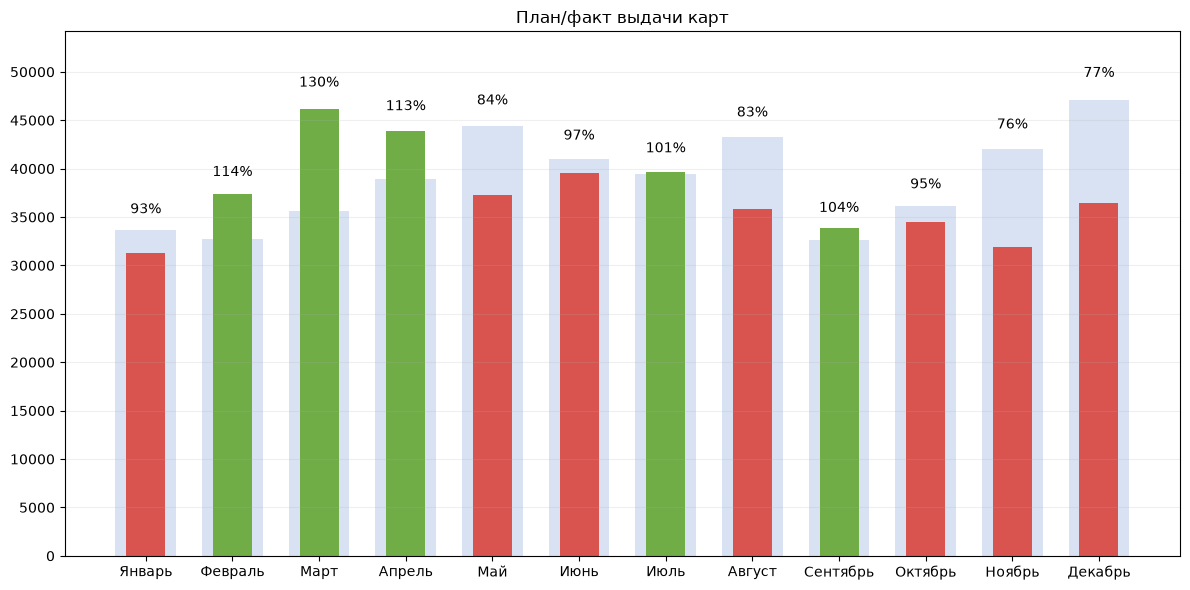

In [9]:
from matplotlib.ticker import MaxNLocator

months = ['Январь', 'Февраль', 'Март', 'Апрель', 'Май', 'Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь', 'Ноябрь', 'Декабрь']

# Суммируем план и факт по всем филиалам и отделениям за каждый месяц
plot_df = df.groupby('Месяц', as_index=False)[['План', 'Факт']].sum()

# Сортируем месяцы в календарном порядке
plot_df['Месяц'] = pd.Categorical(plot_df['Месяц'], categories=months, ordered=True)
plot_df = plot_df.sort_values('Месяц')

x = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x, plot_df['План'], color='#D9E2F3', width=0.7, label='План')
colors = ['#70AD47' if f >= p else '#D9534F' for p, f in zip(plot_df['План'], plot_df['Факт'])]
ax.bar(x, plot_df['Факт'], color=colors, width=0.45, label='Факт')

# Показываем процент выполнения плана над столбцами
for i, row in plot_df.reset_index(drop=True).iterrows():
    percent = row['Факт'] / row['План'] * 100 if row['План'] else 0
    ax.text(i, max(row['План'], row['Факт']) * 1.05, f'{percent:.0f}%', ha='center', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(plot_df['Месяц'].astype(str))
ax.yaxis.set_major_locator(MaxNLocator(nbins=12))
ax.ticklabel_format(axis='y', style='plain')
ax.set_title('План/факт выдачи карт')
ax.grid(axis='y', alpha=0.2)
ax.set_ylim(0, max(plot_df['План'].max(), plot_df['Факт'].max()) * 1.15)
plt.tight_layout()
plt.show()